# ICT 4442 Phase 2 - Clean Retraining Run

This notebook is a fresh rerun of the shared project model. All previous outputs, plots, checkpoints, and metrics were removed before this run.

## Run order and protocol

1. Use a Colab GPU runtime.
2. Run the MLP notebook first: it creates the shared train-only tokenizer.
3. Run CNN and BiLSTM next: they reuse that tokenizer and the same seed/split.
4. DistilBERT uses the same raw review split but its own pretrained WordPiece tokenizer.
5. For the Phase 2 report, record validation evidence only. The held-out test evaluation cells have been removed from these copies.

Google Drive root: `ICT4442_Harsha_Phase2`.


In [5]:
# ── CELL 1 : Installs & Imports ─────────────────────────────────────────────
!pip install -q tensorflow scikit-learn matplotlib seaborn

import os, json, pickle, random, urllib.request, tarfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, Dense, Dropout,
    Conv1D, GlobalMaxPooling1D, Concatenate,
    SpatialDropout1D
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TF version :", tf.__version__)
print("GPU        :", tf.config.list_physical_devices('GPU'))

TF version : 2.20.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
BASE = '/content/ICT4442_Harsha_Phase2'
DRIVE = {'shared': BASE + '/shared', 'weights': BASE + '/CNN/weights', 'history': BASE + '/CNN/history', 'results': BASE + '/CNN/results'}
LOCAL = {'data': '/content/data', 'plots': '/content/plots/CNN'}
for d in list(DRIVE.values()) + list(LOCAL.values()):
    os.makedirs(d, exist_ok=True)
VOCAB_SIZE = 20000
MAX_LEN = 512
EMBED_DIM = 128
print('Using local workspace:', BASE)
print(f'VOCAB_SIZE={VOCAB_SIZE}  MAX_LEN={MAX_LEN}  EMBED_DIM={EMBED_DIM}')

Using local workspace: /content/ICT4442_Harsha_Phase2
VOCAB_SIZE=20000  MAX_LEN=512  EMBED_DIM=128


In [7]:
# ── CELL 3 : Dataset, train/validation split, tokenizer ───────────────────
DATA_PATH = '/content/data/aclImdb'
os.makedirs('/content/data', exist_ok=True)
if not os.path.exists(DATA_PATH):
    print('Downloading IMDb dataset (~84 MB) to local /content ...')
    url = 'https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz'
    urllib.request.urlretrieve(url, '/content/data/aclImdb_v1.tar.gz')
    print('Extracting...')
    with tarfile.open('/content/data/aclImdb_v1.tar.gz', 'r:gz') as t:
        t.extractall('/content/data/')
    os.remove('/content/data/aclImdb_v1.tar.gz')

def load_split(split_dir):
    texts, labels = [], []
    for label_idx, sentiment in enumerate(['neg', 'pos']):
        folder = os.path.join(split_dir, sentiment)
        for fname in sorted(os.listdir(folder)):
            if fname.endswith('.txt'):
                with open(os.path.join(folder, fname), encoding='utf-8') as f:
                    texts.append(f.read())
                labels.append(label_idx)
    return texts, labels

train_texts_full, train_labels_full = load_split(f'{DATA_PATH}/train')
train_texts, val_texts, train_labels_raw, val_labels_raw = train_test_split(
    train_texts_full, train_labels_full, test_size=5000, random_state=SEED, stratify=train_labels_full
)
train_labels = np.array(train_labels_raw)
val_labels = np.array(val_labels_raw)
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(train_texts)
with open(f'{DRIVE["shared"]}/tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)
X_train = pad_sequences(tokenizer.texts_to_sequences(train_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_val = pad_sequences(tokenizer.texts_to_sequences(val_texts), maxlen=MAX_LEN, padding='post', truncating='post')
print(f'Train: {len(train_texts):,}  Val: {len(val_texts):,}')
print(f'X_train: {X_train.shape}  X_val: {X_val.shape}')
print('Tokenizer fitted on training reviews only; held-out test set untouched.')

Extracting...


/tmp/ipykernel_532/2367315667.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall('/content/data/')


Train: 20,000  Val: 5,000
X_train: (20000, 512)  X_val: (5000, 512)
Tokenizer fitted on training reviews only; held-out test set untouched.


In [8]:
# ── CELL 4 : Build 1D-CNN ────────────────────────────────────────────────────
# Architecture decisions:
#   - SpatialDropout1D(0.2) after embedding — same reason as MLP:
#     embedding has 20,000 × 128 = 2.56M params, needs regularization
#   - Three parallel conv branches (kernel 3, 4, 5) — Kim (2014) style
#     captures trigrams, 4-grams, 5-grams simultaneously
#   - GlobalMaxPooling per branch — keeps strongest activation per filter
#   - Single dense layer (64) + Dropout(0.4) + L2 — matches MLP head design
#   - No stacking of multiple conv layers — keeps model simple and
#     academically defensible as a clean CNN baseline

def build_cnn():
    inp = Input(shape=(MAX_LEN,), name='input')

    emb = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBED_DIM,
        name='embedding'
    )(inp)

    # Regularize embedding output — same rationale as MLP SpatialDropout
    emb = SpatialDropout1D(0.3, name='spatial_dropout')(emb)

    # Three parallel conv branches — different receptive fields
    branches = []
    for k in [3, 4, 5]:
        c = Conv1D(
            filters=64,
            kernel_size=k,
            activation='relu',
            name=f'conv_{k}'
        )(emb)
        p = GlobalMaxPooling1D(name=f'pool_{k}')(c)
        branches.append(p)

    # Concatenate — 128 × 3 = 384 features
    x = Concatenate(name='concat')(branches)
    x = Dropout(0.4, name='dropout_1')(x)
    x = Dense(
        64,
        activation='relu',
        kernel_regularizer=l2(1e-4),
        name='dense_1'
    )(x)
    x = Dropout(0.3, name='dropout_2')(x)
    out = Dense(1, activation='sigmoid', name='output')(x)

    model = Model(inputs=inp, outputs=out, name='CNN_1D')
    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    model.build(input_shape=(None, MAX_LEN))
    return model

model = build_cnn()
model.summary()

Model: "CNN_1D"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 512)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 512, 128)  │  2,560,000 │ input[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout     │ (None, 512, 128)  │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_3 (Conv1D)     │ (None, 510, 64)   │     24,640 │ spatial_dropout[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_4 (Conv1D)     │ (None, 509, 64)   │     32,832 │ spatial_dropout[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_5 (Conv1D)     │ (None, 508, 64)   │     41,024 │ spatial_dropout[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_3              │ (None, 64)        │          0 │ conv_3[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_4              │ (None, 64)        │          0 │ conv_4[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_5              │ (None, 64)        │          0 │ conv_5[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat              │ (None, 192)       │          0 │ pool_3[0][0],     │
│ (Concatenate)       │                   │            │ pool_4[0][0],     │
│                     │                   │            │ pool_5[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 192)       │          0 │ concat[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │     12,352 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,670,913 (10.19 MB)

 Trainable params: 2,670,913 (10.19 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# ── CELL 5 : Train 1D-CNN (CPU-friendly batch size) ───────────────────────
CHECKPOINT = f'{DRIVE["weights"]}/cnn_best.keras'
BATCH_SIZE = 512
MAX_EPOCHS = 12
callbacks = [
    EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-6, verbose=1),
    ModelCheckpoint(filepath=CHECKPOINT, monitor='val_loss', save_best_only=True, verbose=1),
]
print(f'Starting training with batch size {BATCH_SIZE}...\n')
history = model.fit(X_train, train_labels, validation_data=(X_val, val_labels), epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
history_data = {
    'model': 'CNN_1D', 'max_len': MAX_LEN, 'batch_size': BATCH_SIZE,
    'epochs_run': len(history.history['loss']),
    'train_loss': history.history['loss'], 'val_loss': history.history['val_loss'],
    'train_accuracy': history.history['accuracy'], 'val_accuracy': history.history['val_accuracy'],
    'lr': [float(lr) for lr in history.history.get('learning_rate', [])],
}
with open(f'{DRIVE["history"]}/cnn_history.json', 'w') as f:
    json.dump(history_data, f, indent=2)
best_epoch = int(np.argmin(history_data['val_loss']) + 1)
print(f'Epochs run: {history_data["epochs_run"]}')
print(f'Best epoch: {best_epoch}')
print(f'Best val_loss: {min(history_data["val_loss"]):.4f}')
print(f'Best val_acc: {max(history_data["val_accuracy"]):.4f}')

Starting training with batch size 512...

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.5056 - loss: 0.7051
Epoch 1: val_loss improved from None to 0.65108, saving model to /content/ICT4442_Harsha_Phase2/CNN/weights/cnn_best.keras

Epoch 1: finished saving model to /content/ICT4442_Harsha_Phase2/CNN/weights/cnn_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 22s 307ms/step - accuracy: 0.5400 - loss: 0.6962 - val_accuracy: 0.6662 - val_loss: 0.6511 - learning_rate: 0.0010
Epoch 2/12
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.6763 - loss: 0.6232
Epoch 2: val_loss improved from 0.65108 to 0.47734, saving model to /content/ICT4442_Harsha_Phase2/CNN/weights/cnn_best.keras

Epoch 2: finished saving model to /content/ICT4442_Harsha_Phase2/CNN/weights/cnn_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 130ms/step - accuracy: 0.7078 - loss: 0.5849 - val_accuracy: 0.7802 - val_loss: 0.4773 - learning_rate: 0.0010
Epoch 3/12
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.79

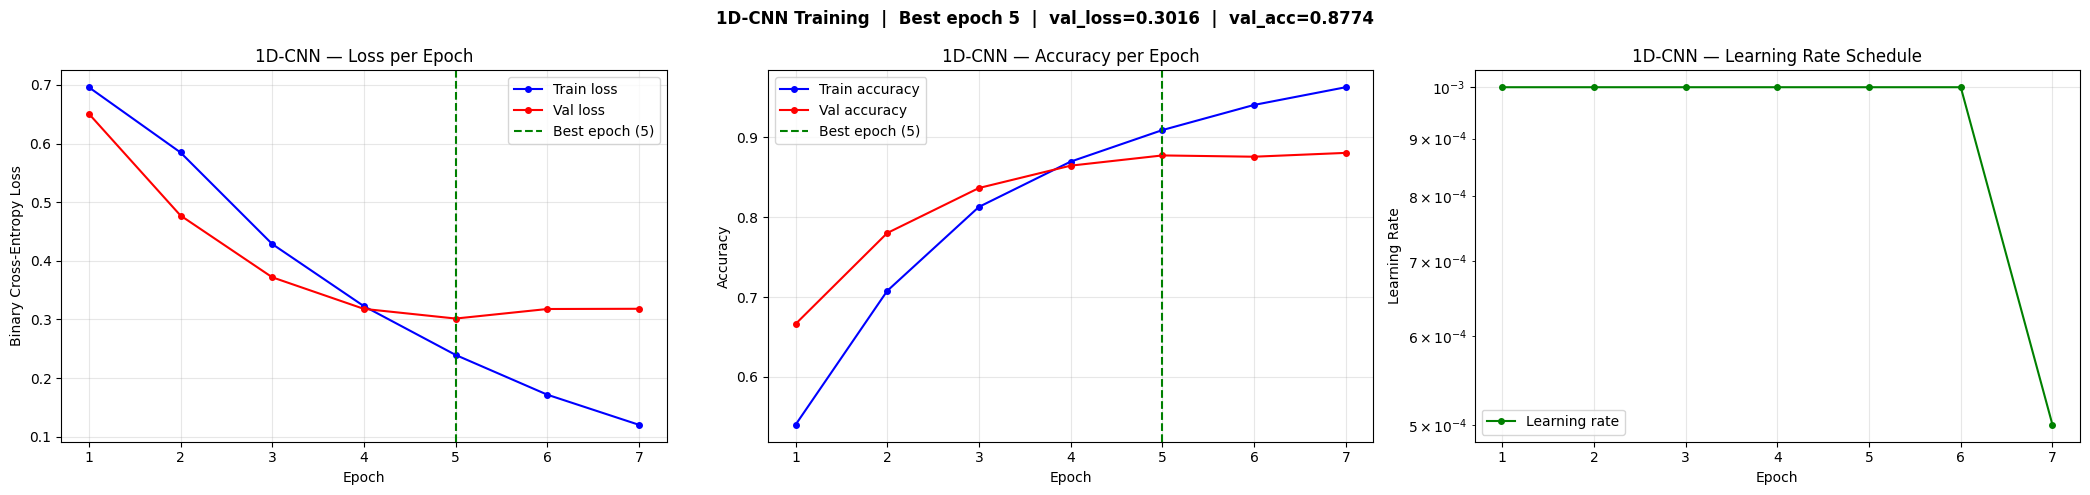

Training curves saved locally.


In [10]:
# ── CELL 6 : Training Curves ─────────────────────────────────────────────────
# To reload and re-plot without retraining:
# with open(f"{DRIVE['history']}/cnn_history.json") as f:
#     history_data = json.load(f)

epochs = range(1, history_data['epochs_run'] + 1)
best_e = np.argmin(history_data['val_loss']) + 1
has_lr = len(history_data['lr']) > 0

n_plots = 3 if has_lr else 2
fig, axes = plt.subplots(1, n_plots, figsize=(7 * n_plots, 5))

# Loss
axes[0].plot(epochs, history_data['train_loss'], 'b-o',
             markersize=4, label='Train loss')
axes[0].plot(epochs, history_data['val_loss'],   'r-o',
             markersize=4, label='Val loss')
axes[0].axvline(best_e, color='green', linestyle='--',
                label=f'Best epoch ({best_e})')
axes[0].set_title('1D-CNN — Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(epochs, history_data['train_accuracy'], 'b-o',
             markersize=4, label='Train accuracy')
axes[1].plot(epochs, history_data['val_accuracy'],   'r-o',
             markersize=4, label='Val accuracy')
axes[1].axvline(best_e, color='green', linestyle='--',
                label=f'Best epoch ({best_e})')
axes[1].set_title('1D-CNN — Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Learning rate (shows ReduceLROnPlateau effect)
if has_lr:
    axes[2].plot(epochs, history_data['lr'], 'g-o',
                 markersize=4, label='Learning rate')
    axes[2].set_title('1D-CNN — Learning Rate Schedule')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Learning Rate')
    axes[2].set_yscale('log')
    axes[2].legend()
    axes[2].grid(alpha=0.3)

plt.suptitle(
    f"1D-CNN Training  |  Best epoch {best_e}  |  "
    f"val_loss={history_data['val_loss'][best_e-1]:.4f}  |  "
    f"val_acc={history_data['val_accuracy'][best_e-1]:.4f}",
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig(f"{LOCAL['plots']}/01_cnn_training_curves.png",
            dpi=150, bbox_inches='tight')
plt.show()
print("Training curves saved locally.")

In [11]:
# ── CELL 7 : Validation Evaluation ───────────────────────────────────────────
val_probs = model.predict(X_val, batch_size=64, verbose=0).flatten()
val_preds = (val_probs >= 0.5).astype(int)

val_metrics = {
    'model'    : 'CNN_1D',
    'split'    : 'validation',
    'max_len'  : MAX_LEN,
    'accuracy' : float(accuracy_score(val_labels,  val_preds)),
    'precision': float(precision_score(val_labels, val_preds)),
    'recall'   : float(recall_score(val_labels,    val_preds)),
    'f1'       : float(f1_score(val_labels,        val_preds)),
    'auc'      : float(roc_auc_score(val_labels,   val_probs)),
}

print("── Validation Metrics ──────────────────────")
for k, v in val_metrics.items():
    if k not in ('model', 'split', 'max_len'):
        print(f"  {k:12s}: {v:.4f}")
print()
print(classification_report(
    val_labels, val_preds,
    target_names=['Negative', 'Positive']
))

# Save to Drive
fpr, tpr, _ = roc_curve(val_labels, val_probs)
roc_val = {
    'fpr': fpr.tolist(),
    'tpr': tpr.tolist(),
    'auc': val_metrics['auc']
}

np.save(f"{DRIVE['results']}/val_probs.npy", val_probs)
np.save(f"{DRIVE['results']}/val_preds.npy", val_preds)
with open(f"{DRIVE['results']}/val_metrics.json", 'w') as f:
    json.dump(val_metrics, f, indent=2)
with open(f"{DRIVE['results']}/roc_val.json", 'w') as f:
    json.dump(roc_val, f)
print("Val probs, preds, metrics, ROC saved to Drive.")

── Validation Metrics ──────────────────────
  accuracy    : 0.8774
  precision   : 0.8551
  recall      : 0.9088
  f1          : 0.8811
  auc         : 0.9505

              precision    recall  f1-score   support

    Negative       0.90      0.85      0.87      2500
    Positive       0.86      0.91      0.88      2500

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000

Val probs, preds, metrics, ROC saved to Drive.


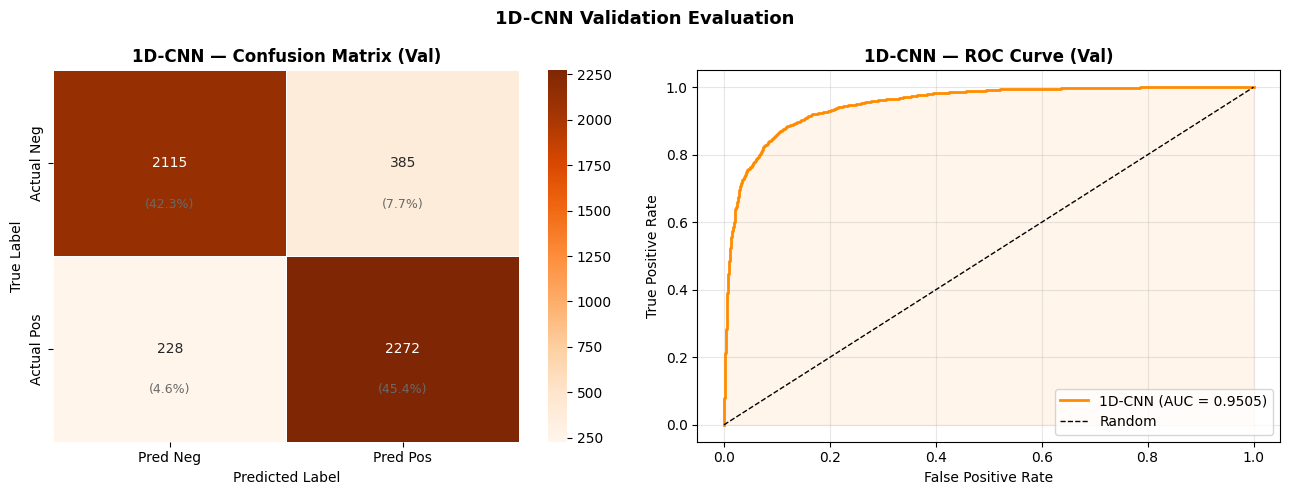

In [12]:
# ── CELL 8 : Confusion Matrix + ROC — Validation ────────────────────────────
# To re-plot without retraining:
# val_probs = np.load(f"{DRIVE['results']}/val_probs.npy")
# val_preds = np.load(f"{DRIVE['results']}/val_preds.npy")
# with open(f"{DRIVE['results']}/roc_val.json") as f:
#     roc_val = json.load(f)

cm = confusion_matrix(val_labels, val_preds)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
    xticklabels=['Pred Neg', 'Pred Pos'],
    yticklabels=['Actual Neg', 'Actual Pos'],
    linewidths=0.5
)
for i in range(2):
    for j in range(2):
        axes[0].text(
            j + 0.5, i + 0.72,
            f"({cm[i,j] / cm.sum() * 100:.1f}%)",
            ha='center', va='center',
            fontsize=9, color='dimgray'
        )
axes[0].set_title('1D-CNN — Confusion Matrix (Val)', fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

axes[1].plot(roc_val['fpr'], roc_val['tpr'],
             color='darkorange', lw=2,
             label=f"1D-CNN (AUC = {roc_val['auc']:.4f})")
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].fill_between(roc_val['fpr'], roc_val['tpr'],
                     alpha=0.08, color='darkorange')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('1D-CNN — ROC Curve (Val)', fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.suptitle('1D-CNN Validation Evaluation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{LOCAL['plots']}/02_cnn_val_cm_roc.png",
            dpi=150, bbox_inches='tight')
plt.show()